# Phân cụm dựa trên lưới với STING

**Học máy · Nhóm 15 · Chủ đề 6 — Grid-based clustering**

Nguyễn Tiến Sơn (24110054) · Trần Thị Ngọc Quyên (24110051)

In [1]:
import ast
import os
import re
import sys
from pathlib import Path

_STING_MARKER = Path("src") / "sting.py"


def _find_repo_root() -> Path:
    seeds: list[Path] = [Path.cwd().resolve()]
    for env_key in ("STING_REPO_ROOT", "SUBMISSION_DEMO_NB_PATH", "JPY_STARTUP_PATH"):
        raw = os.environ.get(env_key)
        if not raw:
            continue
        seeds.append(
            Path(raw).resolve()
            if env_key == "STING_REPO_ROOT"
            else Path(raw).resolve().parent
        )
    try:
        from IPython import get_ipython

        ip = get_ipython()
        if ip is not None:
            for key in ("__vsc_ipynb_file__", "__file__"):
                raw = ip.user_ns.get(key)
                if raw:
                    seeds.append(Path(raw).resolve().parent)
    except ImportError:
        pass
    seen: set[Path] = set()
    for seed in seeds:
        cur = seed
        for _ in range(64):
            if cur in seen:
                break
            seen.add(cur)
            if (cur / _STING_MARKER).is_file():
                return cur
            parent = cur.parent
            if parent == cur:
                break
            cur = parent
    raise FileNotFoundError(
        "Không tìm thấy repo: không có src/sting.py khi đi lên từ cwd hoặc "
        "vị trí notebook — đặt STING_REPO_ROOT hoặc chạy từ thư mục gốc repo."
    )


ROOT = _find_repo_root()
sys.path.insert(0, str(ROOT / "src"))
sys.path.insert(0, str(ROOT / "scripts"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display
from sklearn.datasets import make_blobs
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, DBSCAN
from sklearn.metrics import (
    adjusted_rand_score,
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score,
)

from sting import STING
from papi_pred_common import FEATURE_LABELS, load_config, load_panel
from fig_style import CLUSTER_COLORS, apply_style

apply_style()
print("Đã nạp mã STING và các thư viện phân tích.")

Đã nạp mã STING và các thư viện phân tích.


## 1. Lý thuyết STING

**Grid-based clustering** tìm cụm bằng cách chia không gian dữ liệu thành các ô lưới.
**STING** (Statistical Information Grid) thuộc nhóm phương pháp này và dùng lưới nhiều mức, từ thô đến mịn.
Mỗi ô lưu số điểm và các thống kê tóm tắt.

**Nhóm sử dụng biến thể STING rút gọn, tạo cụm tại một mức lưới**

1. Gán các điểm vào lưới và đếm số điểm trong từng ô.
2. Đánh dấu ô có số điểm đạt ngưỡng là ô dày.
3. Nối các ô dày chung cạnh thành cụm. Điểm trong ô thưa được xem là nhiễu.

## 2. Cài đặt từ đầu — lưới 3 × 3

Ví dụ gồm 15 điểm trên một mặt phẳng. Mỗi ô có ít nhất 3 điểm được xem là ô dày.
Các ô dày chỉ chạm góc được giữ thành những cụm riêng khi dùng quy tắc nối qua cạnh.

In [2]:
counts = np.array([[4, 3, 0], [1, 0, 4], [0, 0, 3]])
positions = [(col, 2 - row) for row in range(3) for col in range(3)]
points = np.repeat(positions, counts.ravel(), axis=0)
model = STING(n_levels=2, factor=3, min_count=3).fit(points)
labels = model.cluster(level=1, connectivity=1)

cell_counts = np.zeros_like(counts)
for (x, y), cell in model.cells_[1].items():
    cell_counts[2 - y, x] = cell.count
print("Số điểm trong từng ô:")
print(cell_counts)
assert np.array_equal(cell_counts, counts)

group_sizes = sorted(np.bincount(labels[labels >= 0]).tolist())
noise_count = int((labels == -1).sum())
assert group_sizes == [7, 7] and noise_count == 1
print(f"{model.n_clusters_} cụm, mỗi cụm {group_sizes[0]} điểm. {noise_count} điểm nhiễu.")

Số điểm trong từng ô:
[[4 3 0]
 [1 0 4]
 [0 0 3]]
2 cụm, mỗi cụm 7 điểm. 1 điểm nhiễu.


## 3. Đánh giá trên dữ liệu giả lập

In [3]:
X_syn, y_true = make_blobs(n_samples=240, centers=[(-6, -6), (6, 6)],
                           cluster_std=0.6, random_state=42)
m_syn = STING(n_levels=3, factor=4, min_count=3).fit(X_syn)
lab_syn = m_syn.cluster(level=2, connectivity=1)
ari = adjusted_rand_score(y_true, lab_syn)
assert ari >= 0.9, f"ARI quá thấp: {ari:.3f}"
print(f"ARI = {ari:.3f} | Số cụm {m_syn.n_clusters_} | Tỷ lệ nhiễu {(lab_syn == -1).mean():.1%}")


ARI = 0.950 | Số cụm 2 | Tỷ lệ nhiễu 2.5%


## 4. Ứng dụng PAPI

- PAPI gồm 882 dòng và 41 cột, theo dõi 63 tỉnh trong giai đoạn 2011–2024.
- Mỗi dòng là một tỉnh trong một năm. Mỗi điểm biểu diễn quan sát đó bằng hai chỉ tiêu đã chọn.
- Hai chỉ tiêu phân cụm là kiểm soát tham nhũng trong cung ứng dịch vụ công và y tế công lập.
- Giá trị 0 được ghi nhận là thiếu theo quy ước của bộ dữ liệu.
- Thống kê chuẩn hóa lấy từ dữ liệu 2011–2023. Cùng phép chuẩn hóa được áp dụng cho năm 2024.
- Phân cụm dùng dữ liệu chuẩn hóa. Biểu đồ dự đoán năm 2024 hiển thị điểm thành phần PAPI gốc; đơn vị được ghi trên trục.

In [4]:
cfg = load_config()
feats = cfg["features"]
panel = load_panel()
assert panel.shape == (882, 41)
print(f"Bảng PAPI có {len(panel)} dòng và {len(panel.columns)} cột.")
print("Hai chỉ tiêu phân cụm")
print("\n".join(f"• {FEATURE_LABELS[feature]}" for feature in feats))

Bảng PAPI có 882 dòng và 41 cột.
Hai chỉ tiêu phân cụm
• 4.2 Kiểm soát tham nhũng trong cung ứng dịch vụ công
• 6.1 Y tế công lập


### 4.1 Tiền xử lý dữ liệu

In [5]:
_prep = pd.read_csv(ROOT / "results" / "preprocessing_audit.csv")
_tbl = _prep[["stage", "test", "result"]].rename(
    columns={"stage": "Giai đoạn", "test": "Kiểm tra", "result": "Kết quả"}
)
_tbl["Giai đoạn"] = _prep["stage"].str[0].map(
    {"1": "Làm sạch", "2": "Tích hợp", "3": "Chuẩn hóa"}
)
_tbl["Kiểm tra"] = _tbl["Kiểm tra"].str.replace(", dedup chạy ĐẦU TIÊN", "", regex=False)
with pd.option_context("display.max_colwidth", None):
    display(_tbl)

,Giai đoạn,Kiểm tra,Kết quả
0,Làm sạch,"Trùng khóa (province_code, year)",0 dòng trùng / 882 dòng (882 khóa duy nhất); trùng toàn dòng: 0
1,Làm sạch,Ô thiếu trong 37 cột chỉ tiêu (8 chiều + tiểu chiều),4649/32634 ô (14.2%); 4284 ô nằm NGOÀI cửa sổ thu thập của cột (d7/sd_7_*/sd_8_*/sd_5_2)
2,Làm sạch,Dòng thiếu ≥1 chỉ tiêu TRONG cửa sổ thu thập,"13/882 dòng, 365 ô; 13 dòng thiếu sd_4_2 hoặc sd_6_1"
3,Làm sạch,Tên tỉnh vs crosswalk 63 tỉnh,0 xung đột; 63/63 mã khớp crosswalk
4,Làm sạch,Khoảng giá trị vs metadata thang đo,0 ô ngoài khoảng / 32634 ô (37 cột × 882 dòng)
5,Làm sạch,Giá trị ngoài cửa sổ thu thập của từng cột,0 ô
6,Làm sạch,Điểm 0.0 (quy ước 'tỉnh không được xếp hạng'),0 ô điểm = 0.0 còn lại
7,Làm sạch,Đánh dấu ngoại lai z-score > 3 (trị tuyệt đối),"122 ô (0.4%), 98 dòng, 29 cột"
8,Tích hợp,Khóa nối duy nhất hai phía + quan hệ bản ghi,panel 0 trùng; master 0 trùng; quan hệ one_to_one (không one-to-many/many-to-many)
9,Tích hợp,Số dòng trước/sau khi nối panel × master,882 → 882; 63 tỉnh; lưới khóa giống nhau: True


In [6]:
ptr = panel[panel.year <= 2023].dropna(subset=feats)
scaler = StandardScaler().fit(ptr[feats])
Xz = scaler.transform(ptr[feats])
m_frozen = STING(n_levels=cfg["sting"]["n_levels"], factor=cfg["sting"]["factor"],
                 min_count=cfg["sting"]["min_count"]).fit(Xz)
lab = m_frozen.cluster(level=cfg["sting"]["cluster_level"],
                       connectivity=cfg["sting"]["connectivity"])
sizes = sorted([int((lab == c).sum()) for c in range(m_frozen.n_clusters_)], reverse=True)
noise = float((lab == -1).mean())
print(f"STING tìm được {m_frozen.n_clusters_} cụm trên {len(ptr)} quan sát giai đoạn 2011–2023.")
print(f"Các cụm có lần lượt {', '.join(map(str, sizes))} điểm. Tỷ lệ nhiễu là {noise:.1%}.")
_exp = pd.read_csv(ROOT / "results" / "metrics.csv")
_sting = _exp[(_exp.scope == "pooled 2011-2023") & (_exp.method == "STING (frozen)")].iloc[0]
_sizes_m = re.search(r"\[(\d+,\s*\d+,\s*\d+)\]", str(_sting.note))
exp_sizes = ast.literal_eval("[" + _sizes_m.group(1) + "]")
assert m_frozen.n_clusters_ == int(_sting.k)
assert sizes == exp_sizes
assert abs(noise - float(_sting.noise_ratio)) < 1e-3

STING tìm được 3 cụm trên 808 quan sát giai đoạn 2011–2023.
Các cụm có lần lượt 629, 16, 5 điểm. Tỷ lệ nhiễu là 19.6%.


In [7]:
saved = pd.read_csv(ROOT / "results" / "predict_all_years.csv", encoding="utf-8-sig")


complete = panel.dropna(subset=feats)
predicted = complete[["year", "province_code"]].assign(
    pred_cluster=m_frozen.predict(scaler.transform(complete[feats]))
)
merged = saved.merge(
    predicted, on=["year", "province_code"],
    suffixes=("_saved", "_refit"), validate="one_to_one",
)
n_diff = int((merged.pred_cluster_saved != merged.pred_cluster_refit).sum())
assert len(merged) == len(saved) == 869
assert n_diff == 0
print(f"Khi chạy lại STING, {len(merged) - n_diff}/{len(saved)} nhãn khớp với kết quả đã lưu.")

Khi chạy lại STING, 869/869 nhãn khớp với kết quả đã lưu.


In [8]:
metrics = pd.read_csv(ROOT / "results" / "metrics.csv")
metrics_pooled = metrics[metrics.scope == "pooled 2011-2023"]
methods = ["STING (frozen)", "k-means k=2", "DBSCAN eps=0.2"]
comparison = metrics_pooled.loc[metrics_pooled.method.isin(methods),
                                ["method", "k", "noise_ratio", "silhouette"]].rename(
    columns={"method": "Phương pháp", "k": "Số cụm",
             "noise_ratio": "Tỷ lệ nhiễu", "silhouette": "Silhouette"}
)
comparison["Phương pháp"] = comparison["Phương pháp"].replace(
    {"STING (frozen)": "STING", "k-means k=2": "K-means (2 cụm)"}
)
print(comparison.to_string(index=False, formatters={"Tỷ lệ nhiễu": "{:.1%}".format}))
print()


def safe_metrics(X, lab):
    mask = lab >= 0
    k = len(set(lab[mask]))
    if k < 2:
        return None, None, None
    return (silhouette_score(X[mask], lab[mask]),
            davies_bouldin_score(X[mask], lab[mask]),
            calinski_harabasz_score(X[mask], lab[mask]))


sil, db, ch = safe_metrics(Xz, lab)
sting_row = metrics_pooled[metrics_pooled.method == "STING (frozen)"].iloc[0]
assert abs(sil - sting_row.silhouette) < 1e-3
assert abs(db - sting_row.davies_bouldin) < 1e-3
assert abs(ch - sting_row.calinski_harabasz) < 1e-1

km2 = KMeans(n_clusters=2, n_init=10, random_state=42).fit(Xz)
km2_row = metrics_pooled[metrics_pooled.method == "k-means k=2"].iloc[0]
assert abs(adjusted_rand_score(lab, km2.labels_) - km2_row.ari_vs_sting) < 1e-3
assert abs(silhouette_score(Xz, km2.labels_) - km2_row.silhouette) < 1e-3

db2 = DBSCAN(eps=0.2, min_samples=5).fit(Xz)
db2_row = metrics_pooled[metrics_pooled.method == "DBSCAN eps=0.2"].iloc[0]
assert abs(adjusted_rand_score(lab, db2.labels_) - db2_row.ari_vs_sting) < 1e-3
print("Kết quả STING, K-means và DBSCAN khớp bảng đối chiếu.")

    Phương pháp  Số cụm Tỷ lệ nhiễu  Silhouette
          STING       3       19.6%       0.361
K-means (2 cụm)       2        0.0%       0.445
 DBSCAN eps=0.2       5       14.2%       0.218



Kết quả STING, K-means và DBSCAN khớp bảng đối chiếu.


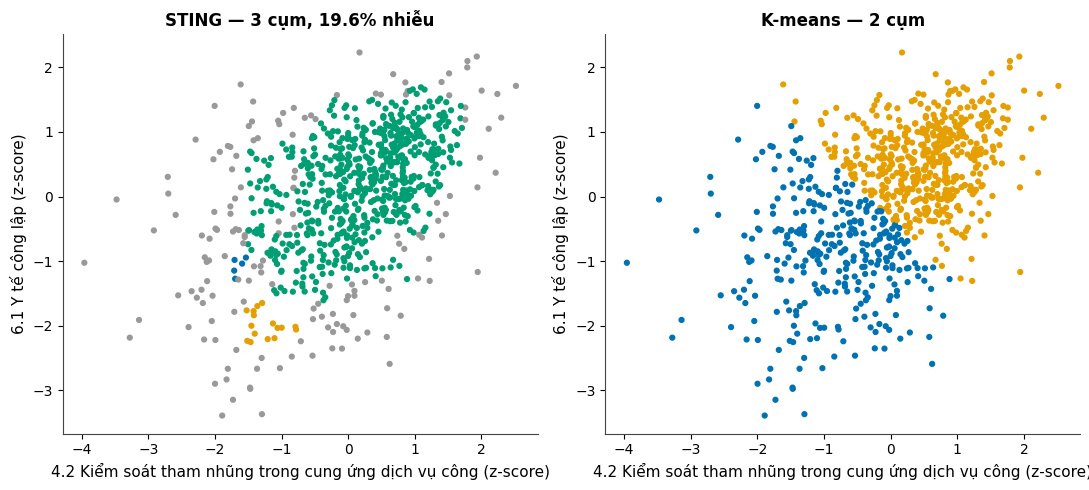

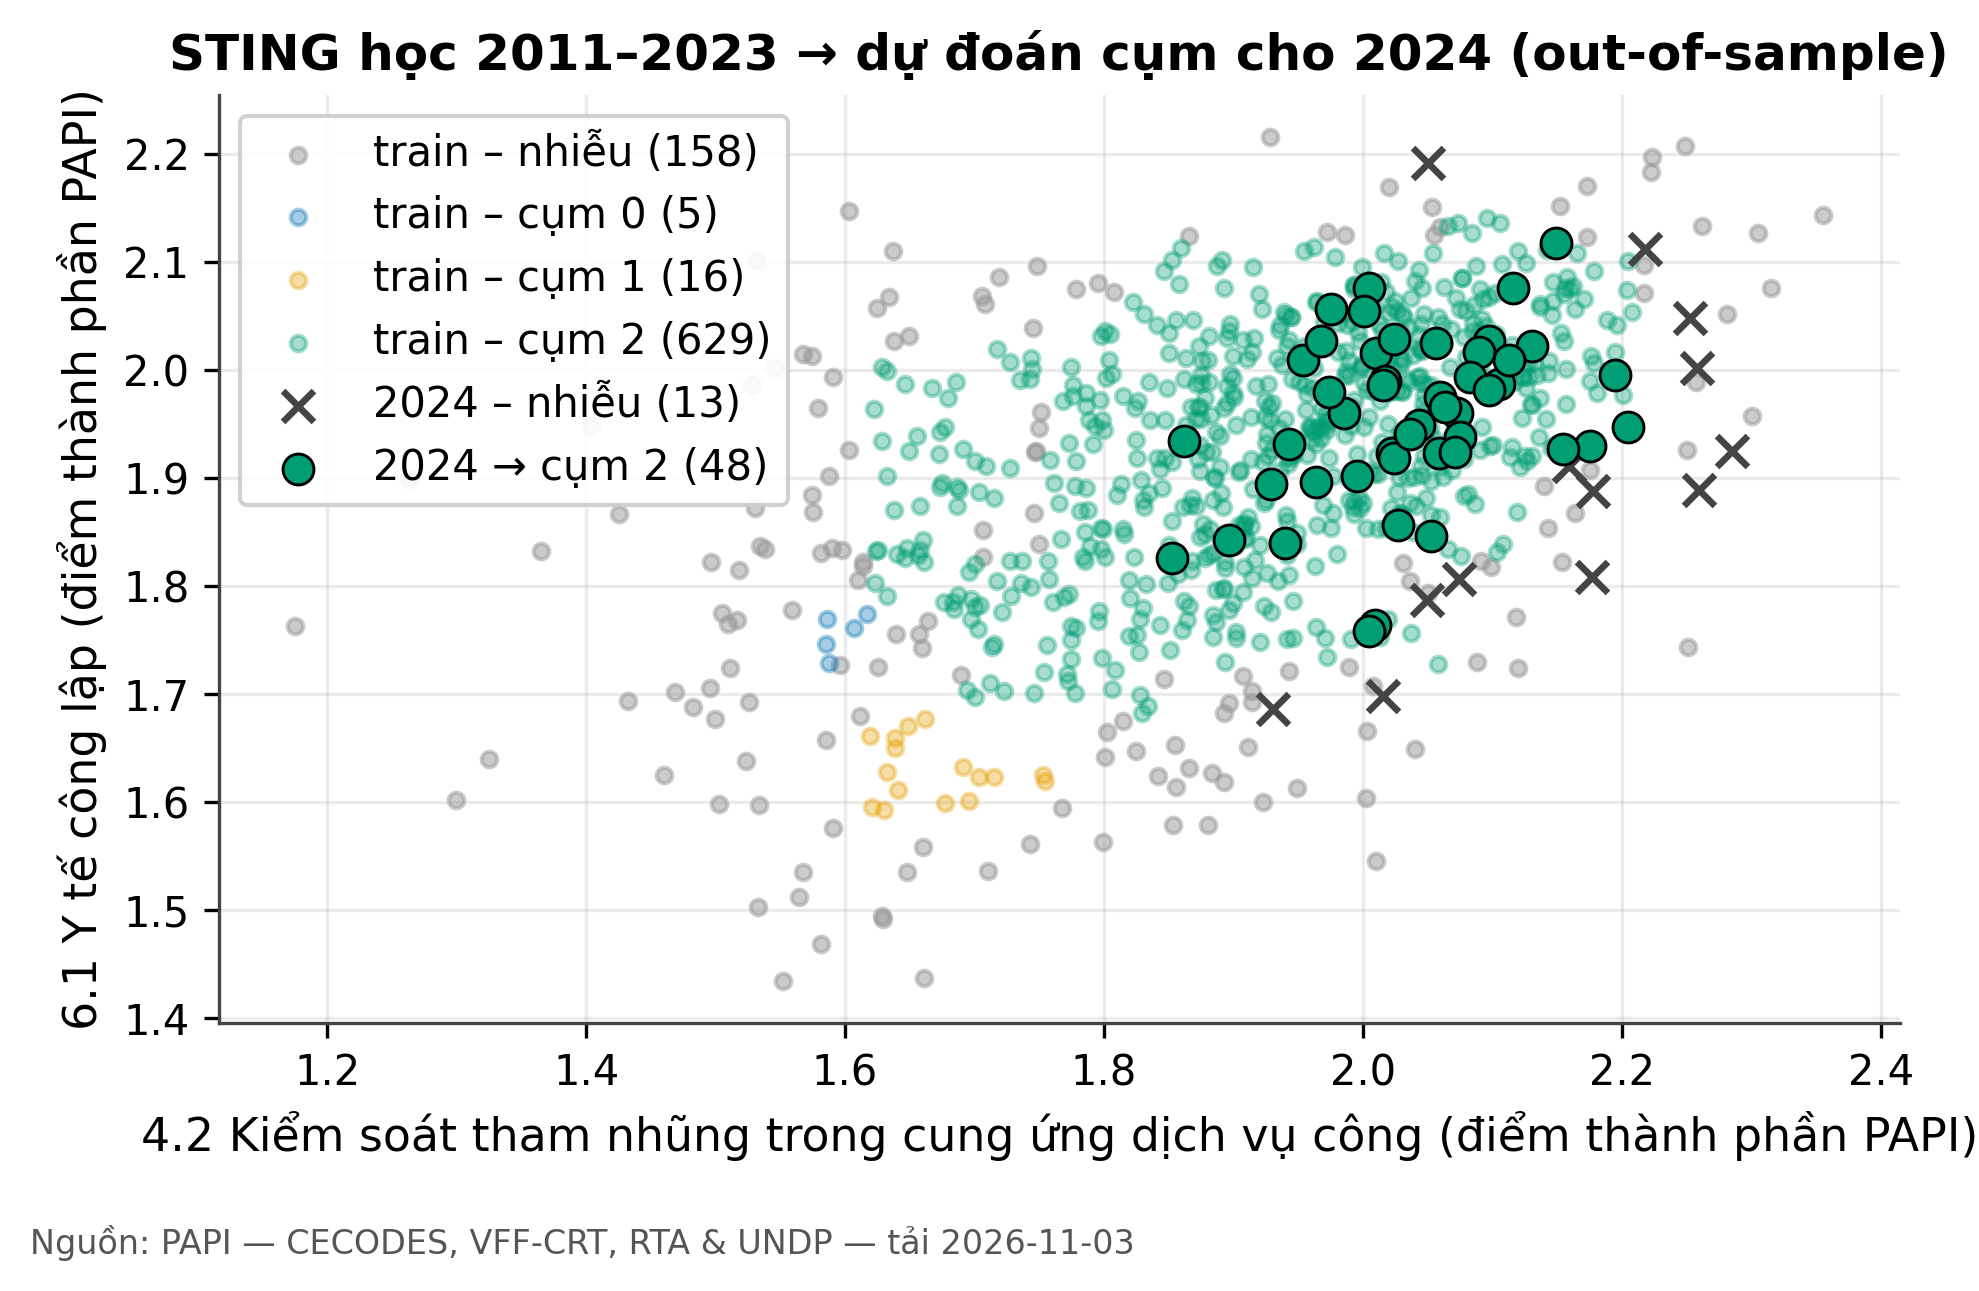

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(11, 5))
axes[0].scatter(Xz[:, 0], Xz[:, 1], s=12, c=[CLUSTER_COLORS[int(c)] for c in lab])
axes[0].set_title(f"STING — {m_frozen.n_clusters_} cụm, {noise:.1%} nhiễu")
axes[1].scatter(Xz[:, 0], Xz[:, 1], s=12, c=[CLUSTER_COLORS[int(c)] for c in km2.labels_])
axes[1].set_title("K-means — 2 cụm")
for ax in axes:
    ax.set_xlabel(f"{FEATURE_LABELS[feats[0]]} (z-score)")
    ax.set_ylabel(f"{FEATURE_LABELS[feats[1]]} (z-score)")
plt.tight_layout()
plt.show()

display(Image(filename=str(ROOT / "results" / "figs" / "predict_2024.png")))

In [10]:
test2024 = panel[panel.year == 2024].dropna(subset=feats)
Xte = scaler.transform(test2024[feats])
base = m_frozen.predict(Xte)
n_provinces = panel.loc[panel.year == 2024, "province_code"].nunique()
n_noise = int((base == -1).sum())
print(f"Năm 2024 có {len(base)}/{n_provinces} tỉnh đủ dữ liệu. "
      f"{len(base) - n_noise} tỉnh được gán cụm, {n_noise} tỉnh nhận nhãn nhiễu.")

min_counts = (3, 5, 8)
sens = []
for mc in min_counts:
    mm = STING(n_levels=cfg["sting"]["n_levels"], factor=cfg["sting"]["factor"],
               min_count=mc).fit(Xz)
    mm.cluster(level=cfg["sting"]["cluster_level"], connectivity=cfg["sting"]["connectivity"])
    p = mm.predict(Xte)
    sens.append((mc, round(float((p != -1).mean()), 2), mm.n_clusters_,
                 round(float(adjusted_rand_score(p, base)), 3)))
print(f"{'Ngưỡng ô dày':>12} | {'Gán cụm 2024':>13} | {'Số cụm 2011–2023':>17} | "
      f"ARI so với ngưỡng {cfg['sting']['min_count']}")
for mc, cov, k, ari in sens:
    print(f"{mc:>12} | {cov:>13.0%} | {k:>17} | {ari:.3f}")
cov_map = {mc: round(cov, 2) for mc, cov, _, _ in sens}
ari_map = {mc: round(ari, 3) for mc, _, _, ari in sens}

def _sensitivity_expectations(md_path):
    exp = {}
    in_tbl = False
    for line in md_path.read_text(encoding="utf-8").splitlines():
        line = line.strip()
        if not line.startswith("|"):
            if in_tbl:
                break
            continue
        cols = [c.strip() for c in line.split("|")[1:-1]]
        if not in_tbl:
            in_tbl = bool(cols) and cols[0] == "min_count"
        elif len(cols) >= 4 and cols[0].isdigit():
            mc = int(cols[0])
            exp[mc] = (float(cols[1].rstrip("%")) / 100, float(cols[3]))
    if exp.keys() != set(min_counts):
        expected = ", ".join(map(str, min_counts))
        raise ValueError(f"Bảng độ nhạy cần đủ các ngưỡng {expected}. Nhận được {sorted(exp)}.")
    return exp

exp_sens = _sensitivity_expectations(ROOT / "results" / "predict_summary.md")
for mc, (ecov, eari) in exp_sens.items():
    assert abs(cov_map[mc] - round(ecov, 2)) < 1e-9
    assert ari_map[mc] == round(eari, 3)


Năm 2024 có 61/63 tỉnh đủ dữ liệu. 48 tỉnh được gán cụm, 13 tỉnh nhận nhãn nhiễu.
Ngưỡng ô dày |  Gán cụm 2024 |  Số cụm 2011–2023 | ARI so với ngưỡng 5
           3 |           82% |                 3 | 0.852
           5 |           79% |                 3 | 1.000
           8 |           70% |                 1 | 0.678


## 5. Kết luận và hạn chế

- Trên dữ liệu giả lập, ARI 0.950 đo độ khớp với nhãn đã biết khi sinh dữ liệu.
- PAPI 2011–2023 có một cụm lớn và hai cụm nhỏ. Số cụm và tỷ lệ nhiễu thay đổi
  theo ngưỡng số điểm. Dữ liệu năm 2024 được gán vào lưới đã học.
- Khi so sánh silhouette, đọc kèm tỷ lệ nhiễu vì mỗi phương pháp có thể được chấm
  trên tập điểm khác nhau. Các cụm mô tả hai chỉ tiêu PAPI được chọn.

**Tài liệu tham khảo:** Wang, Yang & Muntz (VLDB'97); PAPI (CECODES/VFF-CRT/RTA/UNDP);
Le et al., Mendeley Data (DOI 10.17632/wbk42j9wc8.1, CC BY 4.0).